## T-SNE (t-distributed stochastic Neighbor Embedding)
This is a non-linear machine learning algorithim used to visualize high-dimensional data in 2d
or 3d map.
It excels at preserving local structures, meaning similar data points remain close together, making it ideal for 
e.g clustering

### Key aspects of t-SNE
1. Dimensionality reduction.
2. Non-linear technique-> has the ability to capture non-linear in comparison to PCA
3. Optimization- uses gradient descent to minimize the difference between pairwise
similarities in high and low dimensional spaces.

### How t-SNE works?
1. For each pair of points, in the high dimensional space, we are going to compute
the probability that the 2 points are neighbors.
2. Randomly place all points in a low dimensional space e.g 2d.
3. Move points in the low dimensional space so that the neighbor probabilities match
the high-dimensional ones.
4. Iterate until the 2d layout stabilizes.

### The perplexity parameter
This is how many neighbors each point considers.
This balances local and global structures.
- Low perplexity (5-10): May create many small clusters, data looks fragmented.
- Mdeium perplexity (30-50) : Clear, distinct clusters.
- High perplexity (100+): Clusters begine to merge. The visualization starts to look more like PCA


## Use t-SNE only to explore and visualize the structure of your data.
## Never use t-SNE to create features for training a model.
The 2d coorrdinates from t-SNE are not meaningful in absolutr terms(i.e the distance between the clusters are not realible)

t-SNE time complexity-> o(n^2).

In [ ]:
from sklearn.datasets import load_digits

digits = load_digits()


X =digits.data
y =digits.target

In [6]:
# Scaling data
from sklearn.preprocessing import StandardScaler
X_scaled = StandardScaler().fit_transform(X)

In [8]:
# Picking data without replacement
import numpy as np

ids  = np.random.choice(len(X_scaled), 1000, replace = False)
X_sub, y_sub = X[ids], y[ids]


In [10]:
# Running t-sne
from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2,
    perplexity=30,
    max_iter=1000,
    random_state=42
)
X_tsne = tsne.fit_transform(X_sub)

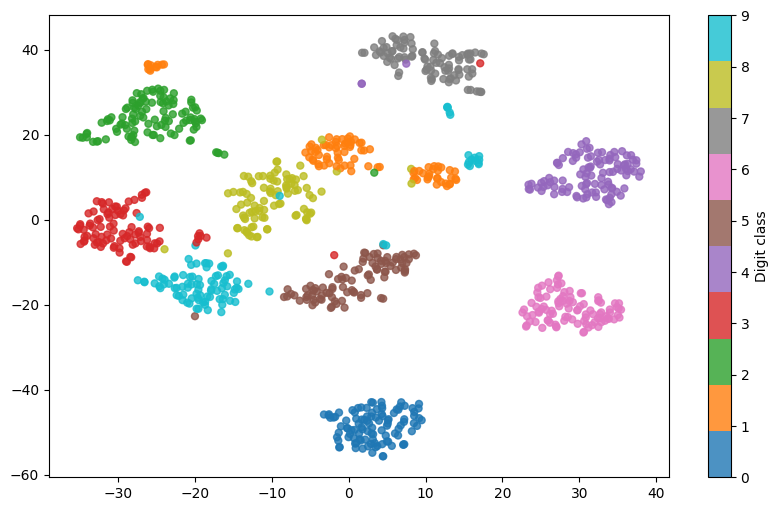

In [12]:
# plotting
from matplotlib.colors import Colormap
import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))
scatter= plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_sub, cmap='tab10', alpha=0.8, s=25)
cbar = plt.colorbar(scatter)
cbar.set_ticks(range(10))
cbar.set_ticklabels([str(i) for i in range(10)])
cbar.set_label('Digit class')


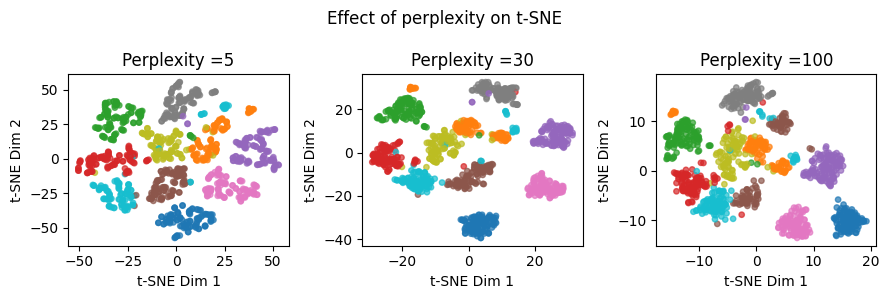

In [15]:
fig, axes =plt.subplots(1,3 ,figsize =(9,3))
perplexities = [5,30,100]

for ax, perp in zip(axes, perplexities):
    tsne = TSNE(
        n_components=2,
        perplexity=perp,
        max_iter=500,
        random_state=42
    )
    X_t = tsne.fit_transform(X_sub)
    scatter = ax.scatter(X_t[:,0],X_t[:,1], c=y_sub, cmap='tab10',alpha=0.7,s=15)
    ax.set_title(f'Perplexity ={perp}')
    ax.set_xlabel('t-SNE Dim 1')
    ax.set_ylabel('t-SNE Dim 2')
    
plt.suptitle('Effect of perplexity on t-SNE')
plt.tight_layout()
plt.show()




# Assingment 1: PCA on the wine dataset
- Load:
``` python
from sklearn.datasets import load_wine
```
- plot the cumulative explained variance and decide how many components to keep.
- Train a logistic regression on the original data and on PCA-reduced data, compare accurac.
- Visualize the first 2 PCA components

## Assingment 2:t-SNE exploration

- Run t-SNE on the same wine data with perplexity values 5, 30 and 100.
- Compare the t-SNE plot to the PCA plot.